# Data Overview

A descriptive look at the creativity ratings before the model-based analysis:
how much data there is, how it is distributed across products and raters, how
well connected the rater–product design is, and the raters' response styles.

This notebook reads the preprocessed data produced by
`00_data_loading_preprocessing.ipynb` (`data/processed/ratings_long_clean.csv`)
and applies the same rater exclusion as the models (raters with fewer than 15
ratings, `results/data/excluded_raters.csv`).
The scoring and reliability analysis is the JRT graded response model in
`../R/` (see `../AUDIT.md`); the checked design tables used by the models
(category use per rater, rater overlap, connectivity) are written by
`../R/01_data_design.R`.

## 1. Load the preprocessed data

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from IPython.display import Markdown

def fmt_cell(v, digits=3):
    # Display formatting only: whole numbers without decimals.
    if isinstance(v, (int, np.integer)) or (isinstance(v, float) and v.is_integer()):
        return f"{int(v)}"
    return f"{v:.{digits}f}" if isinstance(v, float) else str(v)

def show_table(df_table, digits=3):
    # Markdown table without the index column, for embedding in the manuscript.
    # Columns with any non-integer value show all values with decimals (3 -> 3.000);
    # the quantity/value table keeps whole numbers without decimals.
    out = df_table.copy().astype(object)
    for col in out.columns:
        num = pd.to_numeric(df_table[col], errors="coerce")
        dec = col != "value" and num.notna().any() and not (num.dropna() % 1 == 0).all()
        out[col] = [f"{float(v):,.{digits}f}" if dec and pd.notna(n) else fmt_cell(v, digits)
                    for v, n in zip(df_table[col], num)]
    return Markdown(out.to_markdown(index=False, disable_numparse=True))

plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 10
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

PROJECT_ROOT = Path("..").resolve()
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"

df = pd.read_csv(DATA_PROCESSED / "ratings_long_clean.csv")
df["action_id"] = df["action_id"].astype(str)
df["rater_id"] = df["rater_id"].astype(str)

df_old = pd.read_csv(DATA_PROCESSED / "ratings_long_clean_old.csv")
df_old["action_id"] = df_old["action_id"].astype(str)
df_old["rater_id"] = df_old["rater_id"].astype(str)

# Same rater exclusion as the models (fewer than 15 ratings, ../R/01_data_design.R),
# applied to each data set from its own counts, because a rater can pass the cut-off
# only in the newer data. The current list must match results/data/excluded_raters.csv.
MIN_RATINGS_PER_RATER = 15
def below_cutoff(d):
    counts = d["rater_id"].value_counts()
    return counts[counts < MIN_RATINGS_PER_RATER].index

excluded_ids = sorted(below_cutoff(df))
models_excluded = pd.read_csv(PROJECT_ROOT / "results" / "data" / "excluded_raters.csv")
assert set(excluded_ids) == set(models_excluded["rater_id"]), (
    "excluded_raters.csv is out of date: run R/01_data_design.R before this notebook")
n_before = len(df)
df = df[~df["rater_id"].isin(excluded_ids)].copy()
df_old = df_old[~df_old["rater_id"].isin(below_cutoff(df_old))].copy()

print(f"Loaded {n_before} ratings; excluded {n_before - len(df)} ratings from "
      f"{len(excluded_ids)} raters with fewer than 15 ratings "
      f"({', '.join(excluded_ids)}); {len(df)} ratings remain.")
df.head()

Loaded 9503 ratings; excluded 32 ratings from 5 raters with fewer than 15 ratings (R20, R21, R22, R28, R29); 9471 ratings remain.


,rater_id,action_id,rating,technical_correctness,aesthetic_appeal,timestamp,rating_numeric,rating_ordinal,rating_order
0,R27,77f4cd20-ce3c-4e8a-b6a7-6dcfcde3e5f3,1.0,3.0,1.0,2026-10-23 14:26:38.757,1,1,47
1,R25,804fe050-67ca-4bbe-a04b-f5cad5beed34,5.0,4.0,3.0,2026-10-23 11:27:24.382,5,5,103
2,R25,7ce1a402-416c-4ecd-bfc3-eea5fad67744,4.0,5.0,4.0,2026-10-23 11:26:44.684,4,4,102
3,R25,fd3afe07-ed42-46a6-a43f-fa619dc911a4,2.0,3.0,1.0,2026-10-23 11:26:13.078,2,2,101
4,R25,012abd99-d8ad-4044-976f-42af0d62852c,5.0,5.0,5.0,2026-10-23 11:25:38.219,5,5,100


## 2. How much data do we have

Total number of ratings, and how many distinct products and raters they
cover.

In [3]:
print("=" * 80)
print("Data Overview - New Ratings")
print("=" * 80)

print("=" * 80)
print("Data Overview - Old Ratings")
print("=" * 80)

n_ratings_old = len(df_old)
n_actions_old = df_old["action_id"].nunique()
n_raters_old = df_old["rater_id"].nunique()

print("=" * 80)
print(f"Total ratings (old):   {n_ratings_old}")
print(f"Distinct products (old): {n_actions_old}")
print(f"Distinct raters (old):  {n_raters_old}")
print(f"Average ratings per product (old): {n_ratings_old / n_actions_old:.2f}")
print(f"Average ratings per rater (old):  {n_ratings_old / n_raters_old:.1f}")


print("=" * 80)
n_ratings = len(df)
n_actions = df["action_id"].nunique()
n_raters = df["rater_id"].nunique()

print(f"Total ratings:   {n_ratings}")
print(f"Distinct products: {n_actions}")
print(f"Distinct raters:  {n_raters}")
print(f"Average ratings per product: {n_ratings / n_actions:.2f}")
print(f"Average ratings per rater:  {n_ratings / n_raters:.1f}")



Data Overview - New Ratings
Data Overview - Old Ratings
Total ratings (old):   7820
Distinct products (old): 3668
Distinct raters (old):  19
Average ratings per product (old): 2.13
Average ratings per rater (old):  411.6
Total ratings:   9471
Distinct products: 3840
Distinct raters:  24
Average ratings per product: 2.47
Average ratings per rater:  394.6


## 3. Distribution of the number of ratings

Some products have only one rating and contribute no within-product
agreement information; some raters have rated far more products than
others. Both matter for how much we can trust the eventual reliability
estimates.

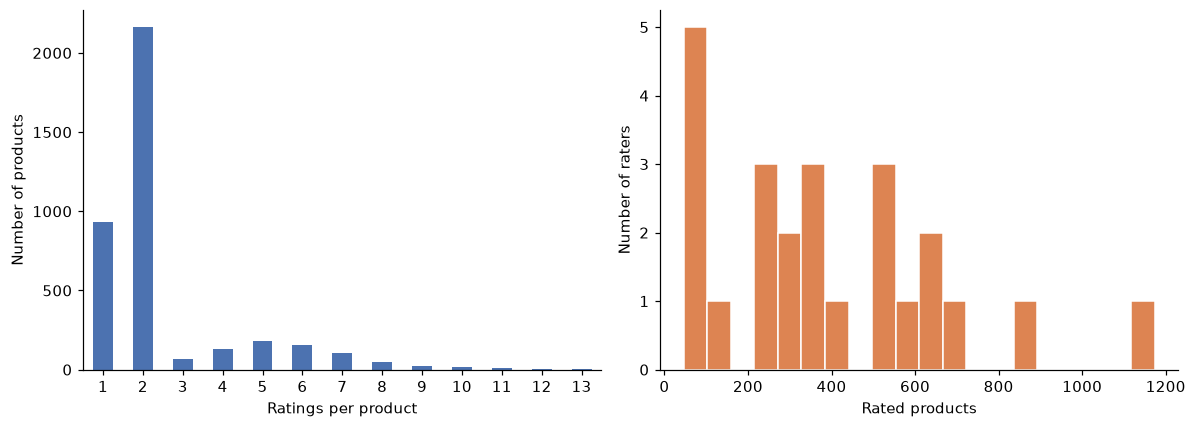

In [4]:
ratings_per_action_old = df_old.groupby("action_id").size().rename("n_ratings")
ratings_per_rater_old = df_old.groupby("rater_id").size().rename("n_actions_rated")
ratings_cum_old = ratings_per_action_old.value_counts().sort_index(ascending=False).cumsum()
ratings_cum_old = ratings_cum_old.sort_index(ascending=True)
ratings_cum_old.index = [f"{x} or more ratings" for x in ratings_cum_old.index]

ratings_per_action = df.groupby("action_id").size().rename("n_ratings")
ratings_per_rater = df.groupby("rater_id").size().rename("n_actions_rated")
ratings_cum = ratings_per_action.value_counts().sort_index(ascending=False).cumsum()
ratings_cum = ratings_cum.sort_index(ascending=True)
ratings_cum.index = [f"{x} or more ratings" for x in ratings_cum.index]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ratings_per_action.value_counts().sort_index().plot(kind="bar", ax=axes[0], color="#4C72B0")
axes[0].set_xlabel("Ratings per product")
axes[0].set_ylabel("Number of products")
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=0)

axes[1].hist(ratings_per_rater.values, bins=min(20, n_raters), color="#DD8452", edgecolor="white")
axes[1].set_xlabel("Rated products")
axes[1].set_ylabel("Number of raters")
fig.tight_layout()
plt.show()

In [5]:
df_before_vs_after = pd.DataFrame({
    "products before": ratings_cum_old,
    "products after": ratings_cum,
}).fillna(0).astype(int).loc[["1 or more ratings", "2 or more ratings", "3 or more ratings", "4 or more ratings", "5 or more ratings", "6 or more ratings", "7 or more ratings", "8 or more ratings", "9 or more ratings", "10 or more ratings", "11 or more ratings"]]

df_before_vs_after['change'] = df_before_vs_after['products after'] - df_before_vs_after['products before']

df_before_vs_after

,products before,products after,change
1 or more ratings,3668,3840,172
2 or more ratings,2771,2905,134
3 or more ratings,691,742,51
4 or more ratings,334,672,338
5 or more ratings,209,544,335
6 or more ratings,84,365,281
7 or more ratings,37,207,170
8 or more ratings,17,99,82
9 or more ratings,6,52,46
10 or more ratings,3,27,24


In [6]:
print("=" * 80)
print("Latest timestamp in df_old:")
print("=" * 80)

print(pd.to_datetime(df_old.timestamp).max())

print("Latest rating timestamp in df:")
print("=" * 80)
print(pd.to_datetime(df.timestamp).max())

print("Time since last freeze of old ratings:")
print("=" * 80)

print(pd.to_datetime(df.timestamp).max() - pd.to_datetime(df_old.timestamp).max())


Latest timestamp in df_old:
2026-10-08 08:56:03.403000
Latest rating timestamp in df:
2026-11-08 21:40:34.177000
Time since last freeze of old ratings:
31 days 12:44:30.774000


In [7]:
print("=" * 80)
print("Number of additional ratings since last freeze of old ratings:")
print("=" * 80)
print(df.shape[0] - df_old.shape[0])

print("Number of additional ratings per week: ")
print("=" * 80)
print(f"{(df.shape[0] - df_old.shape[0]) / (pd.to_datetime(df.timestamp).max() - pd.to_datetime(df_old.timestamp).max()).days * 7:.1f}")

Number of additional ratings since last freeze of old ratings:
1651
Number of additional ratings per week: 
372.8


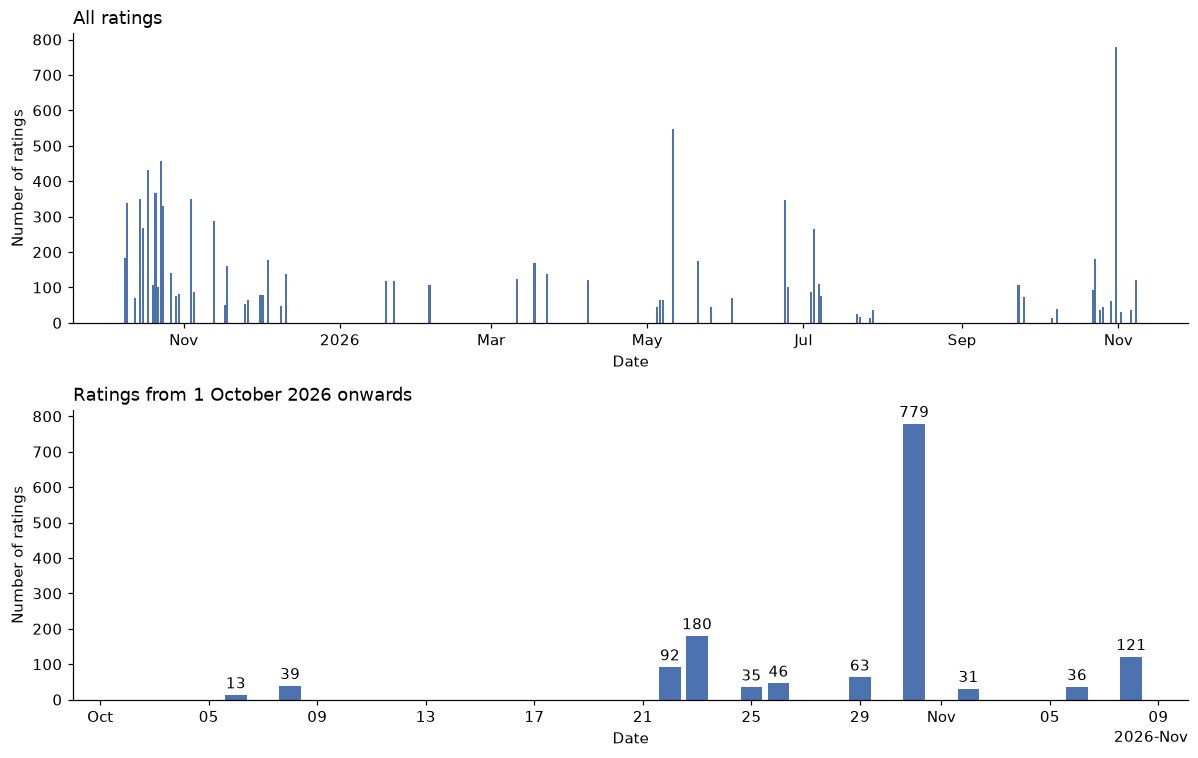

In [8]:
import matplotlib.dates as mdates

# Ratings per calendar day. Timestamps are strings in df, so parse them first;
# normalize() drops the time of day. Days without ratings appear as gaps.
ratings_per_day = pd.to_datetime(df["timestamp"]).dt.normalize().value_counts().sort_index()

recent_start = pd.Timestamp("2026-10-01")
ratings_per_day_recent = ratings_per_day[ratings_per_day.index >= recent_start]

fig, axes = plt.subplots(2, 1, figsize=(11, 7))
panels = [
    (axes[0], ratings_per_day, "All ratings"),
    (axes[1], ratings_per_day_recent, "Ratings from 1 October 2026 onwards"),
]
for ax, counts, title in panels:
    ax.bar(counts.index, counts.values, width=0.8, color="#4C72B0")
    locator = mdates.AutoDateLocator(minticks=5, maxticks=14)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    ax.set_xlabel("Date")
    ax.set_ylabel("Number of ratings")
    ax.set_title(title, loc="left")

# Start the second panel's axis at 1 October, even though the first ratings come later.
axes[1].set_xlim(left=recent_start - pd.Timedelta(days=1))

# Count on top of each bar in the lower panel.
axes[1].bar_label(axes[1].containers[0], padding=2)

fig.tight_layout()
plt.show()

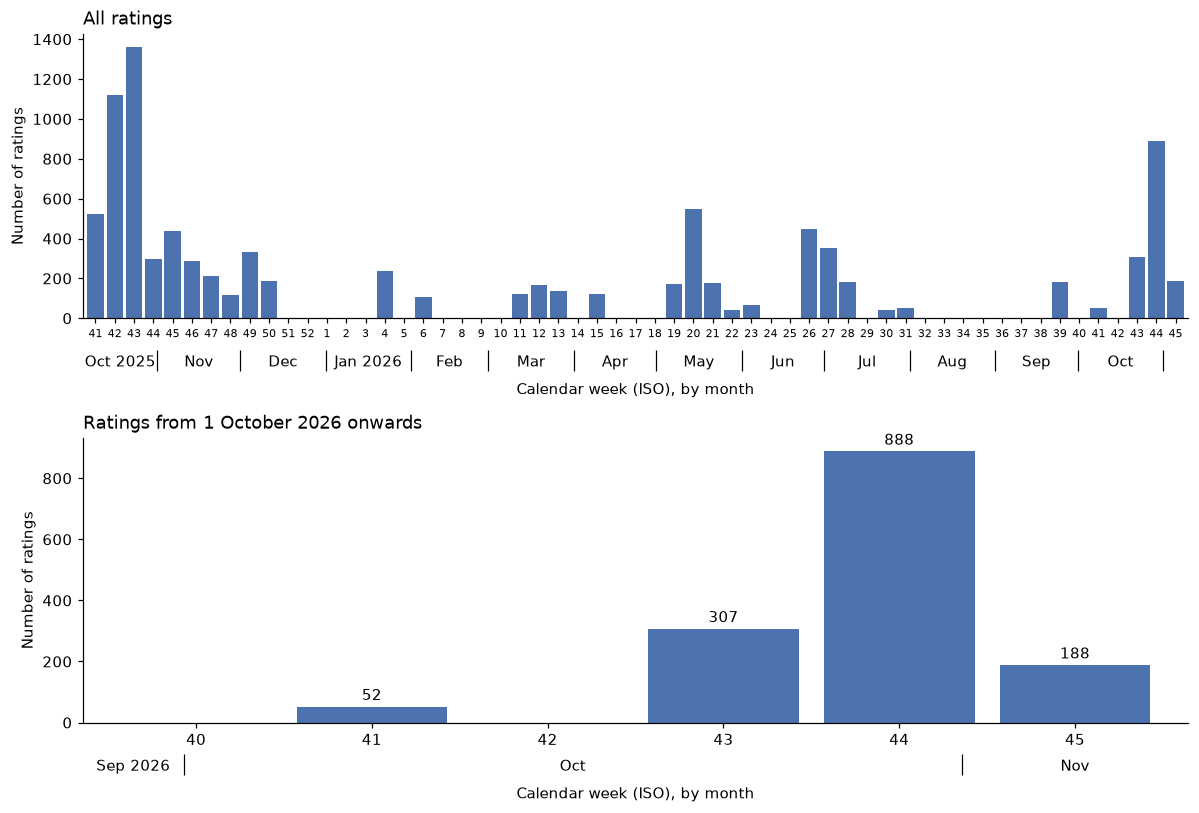

In [9]:
import calendar

# Ratings per ISO calendar week (Monday to Sunday), with a month row below the week
# numbers. Week numbers repeat across years, so the month row also shows the year.
# The recent data is filtered before binning, so its first bar only counts ratings
# from 1 October onwards, not the earlier days of that week.
timestamps = pd.to_datetime(df["timestamp"])

def count_per_week(ts, first_week=None):
    # Counts for every week in the range, so weeks without ratings still get a label.
    counts = ts.dt.to_period("W-SUN").dt.start_time.value_counts()
    first_week = counts.index.min() if first_week is None else first_week
    weeks = pd.date_range(first_week, counts.index.max(), freq="W-MON")
    return counts.reindex(weeks, fill_value=0)

def add_month_row(ax, first_day, last_day):
    # Second x-axis row: separators at month boundaries, month names centred between them.
    x_min, x_max = mdates.date2num(first_day), mdates.date2num(last_day)
    months = pd.date_range(first_day.to_period("M").start_time, last_day, freq="MS")
    edges = [x_min, *mdates.date2num(months[1:]), x_max]
    centres, labels = [], []
    for i, (month, left, right) in enumerate(zip(months, edges[:-1], edges[1:])):
        if (right - left) / (x_max - x_min) < 0.03:
            continue  # too narrow to hold a label
        name = calendar.month_abbr[month.month]
        centres.append((left + right) / 2)
        labels.append(f"{name} {month.year}" if i == 0 or month.month == 1 else name)
    row = ax.secondary_xaxis(-0.11)
    row.spines["bottom"].set_visible(False)
    row.set_xticks(edges[1:-1], labels=[])
    row.tick_params(axis="x", which="major", length=14, direction="out")
    row.set_xticks(centres, labels=labels, minor=True)
    row.tick_params(axis="x", which="minor", length=0)
    row.set_xlabel("Calendar week (ISO), by month")

recent_first_week = recent_start.to_period("W-SUN").start_time
ratings_per_week = count_per_week(timestamps)
ratings_per_week_recent = count_per_week(timestamps[timestamps >= recent_start], recent_first_week)

fig, axes = plt.subplots(2, 1, figsize=(11, 7.5))
panels = [
    (axes[0], ratings_per_week, "All ratings", 7),
    (axes[1], ratings_per_week_recent, "Ratings from 1 October 2026 onwards", 10),
]
for ax, counts, title, week_fontsize in panels:
    # Bars and week labels sit in the middle of each week.
    centres = counts.index + pd.Timedelta(days=3.5)
    ax.bar(centres, counts.values, width=6, color="#4C72B0")
    ax.set_xticks(centres, labels=counts.index.isocalendar().week.astype(int).astype(str))
    ax.tick_params(axis="x", labelsize=week_fontsize)
    ax.set_ylabel("Number of ratings")
    ax.set_title(title, loc="left")

    first_day = counts.index[0] - pd.Timedelta(days=1)
    last_day = counts.index[-1] + pd.Timedelta(days=8)
    ax.set_xlim(first_day, last_day)
    add_month_row(ax, first_day, last_day)

# Count on top of each bar in the lower panel; weeks without ratings stay unlabelled.
axes[1].bar_label(
    axes[1].containers[0],
    labels=[str(n) if n else "" for n in ratings_per_week_recent.values],
    padding=2,
)

fig.tight_layout()
plt.show()

In [10]:
ratings_per_day

timestamp
2025-10-09    183
2025-10-10    339
2025-10-13     69
2025-10-15    350
2025-10-16    269
             ... 
2026-10-29     63
2026-10-31    779
2026-11-02     31
2026-11-06     36
2026-11-08    121
Name: count, Length: 64, dtype: int64

In [11]:
df[
    (pd.to_datetime(df.timestamp) >= pd.to_datetime('2026-10-31') ) & (
        pd.to_datetime(df.timestamp) < pd.to_datetime('2026-11-01')
    )
].rater_id.value_counts().sort_index()

rater_id
R23    589
R24    190
Name: count, dtype: int64